# **📉 IT Customer Churn Prediction – ML Models**
**What this notebook does (step by step):**
1. Load & understand the data
2. Clean the data
3. Explore (EDA) – who churns?
4. Prepare features
5. Train models: Baseline → Logistic Regression → Decision Tree → Random Forest → Gradient Boosting
6. Compare results & tune the best model
7. Feature importance & conclusion

**Goal:** predict whether a customer will leave (`Churn` = Yes/No). Since only ~27% churn, we judge models by **ROC-AUC, Recall and F1**, not accuracy alone.

## **1. Import Libraries**

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)
sns.set_style('whitegrid')

## **2. Load Data**

In [2]:
import os
path = next((os.path.join(d,f) for d,_,fs in os.walk('/kaggle/input') for f in fs if f.endswith('.csv')), '/kaggle/input/datasets/alipakzad/telecom-customer-churn/IT_customer_churn.csv') if os.path.exists('/kaggle/input') else 'IT_customer_churn.csv'
df = pd.read_csv(path)
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


## **3. Data Cleaning**
`TotalCharges` is stored as text because some rows are blank (new customers with tenure 0). We convert it to numbers and fill blanks with 0 (they have paid nothing yet).

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Blank TotalCharges:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['Churn'] = (df['Churn']=='Yes').astype(int)   # Yes=1, No=0
print('Duplicates:', df.duplicated().sum())
df['Churn'].value_counts(normalize=True)

Blank TotalCharges: 11
Duplicates: 22


Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

## **4. Exploratory Data Analysis (EDA)**

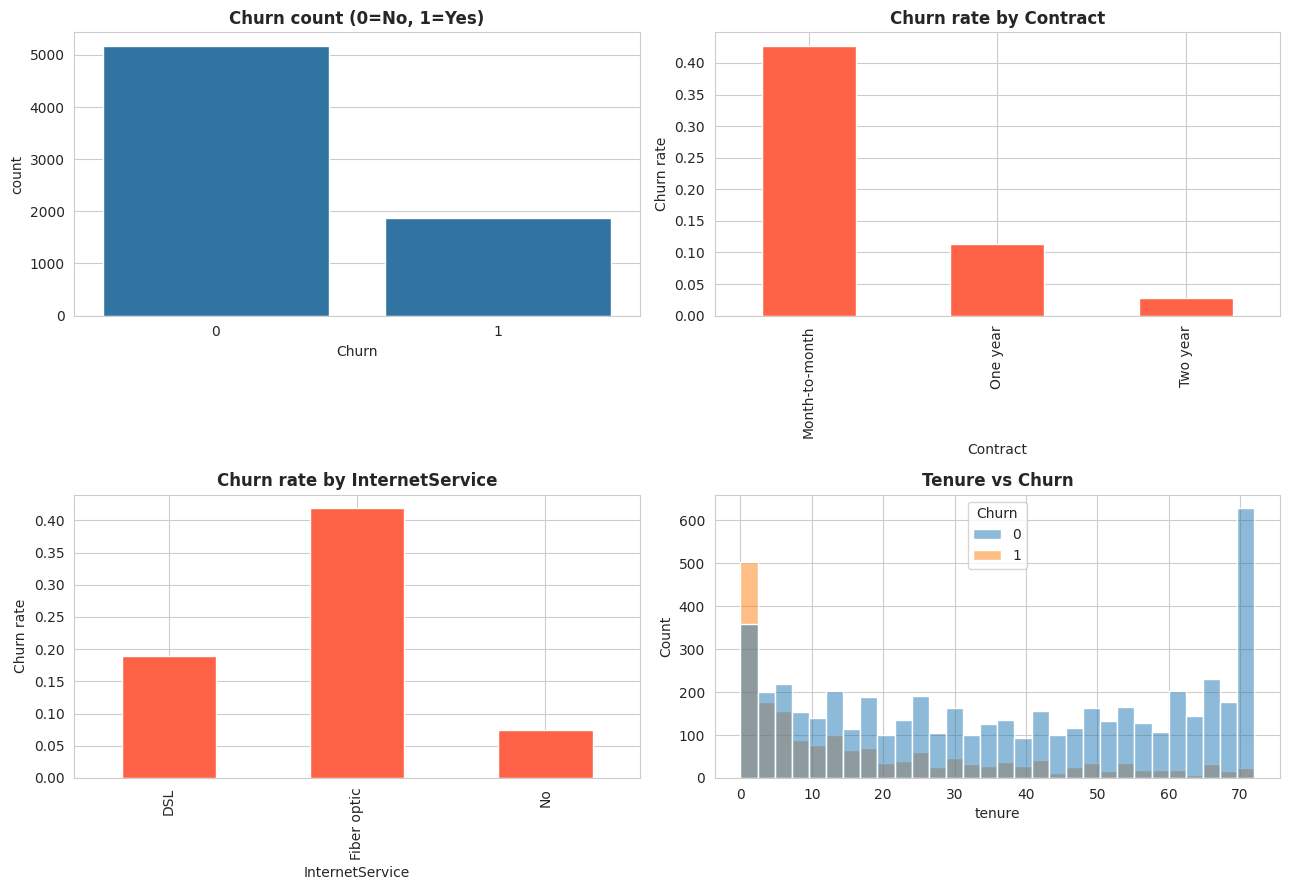

In [5]:
fig, ax = plt.subplots(2,2, figsize=(13,9))
sns.countplot(x='Churn', data=df, ax=ax[0,0]); ax[0,0].set_title('Churn count (0=No, 1=Yes)',fontweight='bold')
for col, a in zip(['Contract','InternetService'], [ax[0,1], ax[1,0]]):
    df.groupby(col)['Churn'].mean().plot.bar(ax=a, color='tomato'); a.set_title(f'Churn rate by {col}',fontweight='bold'); a.set_ylabel('Churn rate')
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=ax[1,1]); ax[1,1].set_title('Tenure vs Churn',fontweight='bold')
plt.tight_layout(); plt.show()

**Insights:** customers on *month-to-month* contracts, with *fiber optic* internet and *low tenure* churn the most. Long-term contracts keep customers.

## **5. Feature Engineering**
We add a few simple, meaningful features, then convert text columns to numbers (one-hot encoding).

In [6]:
d = df.copy()
d['AvgMonthlySpend'] = d['TotalCharges']/(d['tenure']+1)
d['NumServices'] = (d[['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']]=='Yes').sum(axis=1)
d['IsNewCustomer'] = (d['tenure']<=12).astype(int)
X = pd.get_dummies(d.drop('Churn',axis=1), drop_first=True)
y = d['Churn']
print(X.shape)

(7043, 33)


## **6. Train / Test Split**
80% train, 20% test. `stratify=y` keeps the same churn ratio in both parts.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
num = ['tenure','MonthlyCharges','TotalCharges','AvgMonthlySpend','NumServices']
scale = ColumnTransformer([('s', StandardScaler(), num)], remainder='passthrough')  # scaling helps Logistic Regression

## **7. Train Models: Baseline → Best**
We use `class_weight='balanced'` where possible so the model pays attention to the smaller churn group.

In [8]:
models = {
 'Baseline (Dummy)'   : DummyClassifier(strategy='most_frequent'),
 'Logistic Regression': Pipeline([('sc',scale),('m',LogisticRegression(max_iter=2000, class_weight='balanced'))]),
 'Decision Tree'      : DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
 'Random Forest'      : RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1),
 'Gradient Boosting'  : GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    m.fit(X_train, y_train); fitted[name]=m
    pred = m.predict(X_test); prob = m.predict_proba(X_test)[:,1]
    rows.append([name, accuracy_score(y_test,pred), precision_score(y_test,pred,zero_division=0),
                 recall_score(y_test,pred), f1_score(y_test,pred), roc_auc_score(y_test,prob)])
res = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1','ROC-AUC']).set_index('Model').round(3)
res.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.740,0.506,0.783,0.615,0.846
Gradient Boosting,0.802,0.667,0.508,0.577,0.845
Random Forest,0.757,0.530,0.767,0.627,0.843
Decision Tree,0.724,0.488,0.810,0.609,0.828
Baseline (Dummy),0.735,0.000,0.000,0.000,0.500


**Note:** the Dummy baseline gets ~73% accuracy by always predicting 'No churn' – but its recall is 0. That's why accuracy alone is misleading here.

## **8. Hyperparameter Tuning (Best Model)**
We tune Gradient Boosting with 5-fold cross-validation, scoring on ROC-AUC.

In [9]:
grid = {'n_estimators':[100,200], 'learning_rate':[0.03,0.05,0.1], 'max_depth':[2,3], 'subsample':[0.8,1.0]}
gs = GridSearchCV(GradientBoostingClassifier(random_state=42), grid, scoring='roc_auc',
                  cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
gs.fit(X_train, y_train)
best = gs.best_estimator_
print('Best params:', gs.best_params_)
print('CV ROC-AUC :', round(gs.best_score_,3))

Best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}
CV ROC-AUC : 0.85


## **9. Threshold Tuning**
By default a model says 'churn' if probability > 0.5. For churn we care about **catching leavers**, so we pick the threshold that gives the best F1 on the training data (via cross-validated predictions – no peeking at test data).

In [10]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(best, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=1), method='predict_proba')[:,1]
ths = np.arange(0.2,0.7,0.01)
th = ths[np.argmax([f1_score(y_train, oof>t) for t in ths])]
print('Best threshold:', round(th,2))

Best threshold: 0.27


## **10. Final Model Evaluation**

In [11]:
prob = best.predict_proba(X_test)[:,1]; pred = (prob>=th).astype(int)
final = pd.DataFrame({'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred),
        'Recall':recall_score(y_test,pred),'F1':f1_score(y_test,pred),'ROC-AUC':roc_auc_score(y_test,prob)}, index=['Tuned Gradient Boosting']).round(3)
display(pd.concat([res, final]).sort_values('ROC-AUC', ascending=False))
print(classification_report(y_test, pred, target_names=['No Churn','Churn']))

,Accuracy,Precision,Recall,F1,ROC-AUC
Tuned Gradient Boosting,0.746,0.514,0.791,0.623,0.847
Logistic Regression,0.740,0.506,0.783,0.615,0.846
Gradient Boosting,0.802,0.667,0.508,0.577,0.845
Random Forest,0.757,0.530,0.767,0.627,0.843
Decision Tree,0.724,0.488,0.810,0.609,0.828
Baseline (Dummy),0.735,0.000,0.000,0.000,0.500


              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



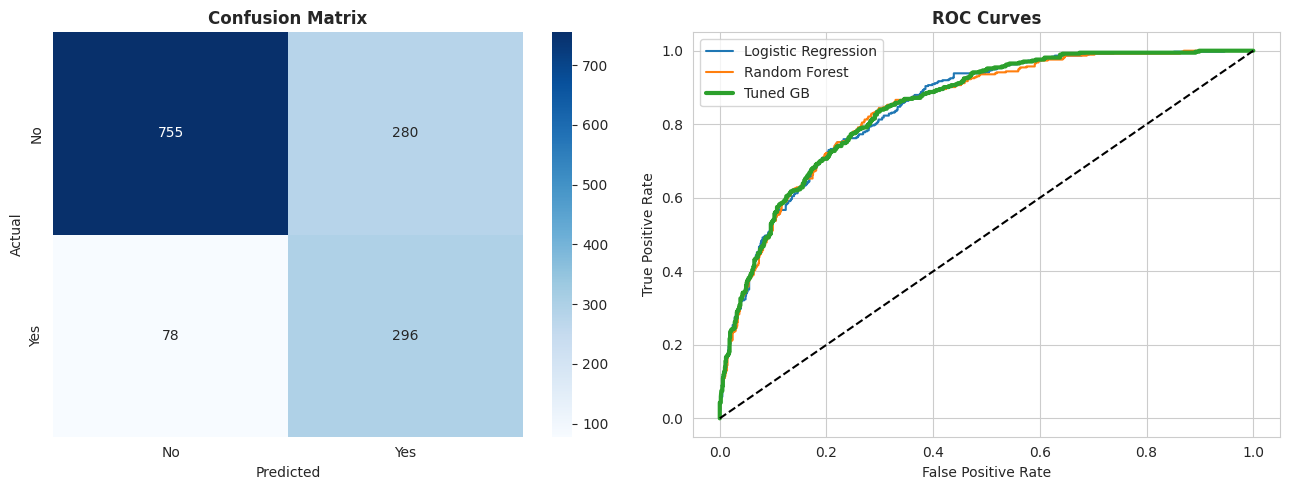

In [12]:
fig, ax = plt.subplots(1,2, figsize=(13,5))
sns.heatmap(confusion_matrix(y_test,pred), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['No','Yes'], yticklabels=['No','Yes']); ax[0].set_title('Confusion Matrix',fontweight='bold'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
for n in ['Logistic Regression','Random Forest']:
    f,t,_ = roc_curve(y_test, fitted[n].predict_proba(X_test)[:,1]); ax[1].plot(f,t,label=n)
f,t,_ = roc_curve(y_test, prob); ax[1].plot(f,t,label='Tuned GB', lw=3)
ax[1].plot([0,1],[0,1],'k--'); ax[1].set_title('ROC Curves',fontweight='bold'); ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate'); ax[1].legend()
plt.tight_layout(); plt.show()

## **11. What Drives Churn? (Feature Importance)**

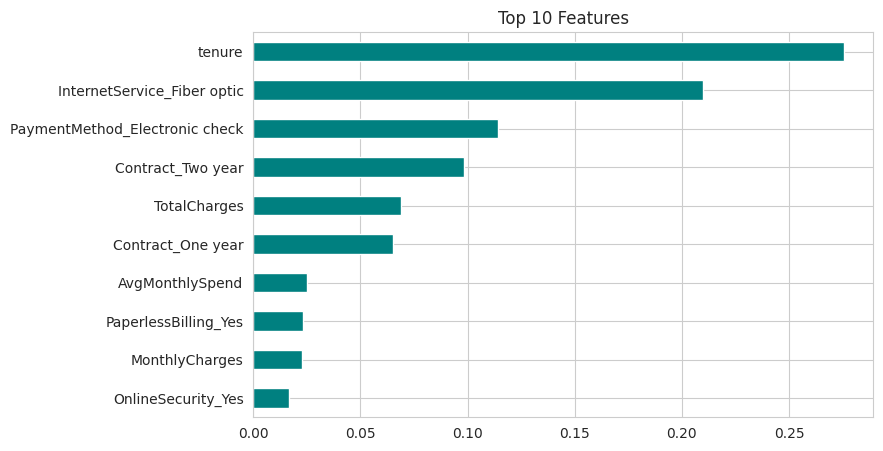

In [13]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot.barh(color='teal', figsize=(8,5), title='Top 10 Features'); plt.show()

## **12. Conclusion**

### **Key results**
| Model | ROC-AUC | Recall (churn) | F1 |
|---|---|---|---|
| Baseline (Dummy) | 0.500 | 0.00 | 0.00 |
| Decision Tree | 0.828 | 0.81 | 0.61 |
| Random Forest | 0.843 | 0.77 | 0.63 |
| Gradient Boosting (default) | 0.845 | 0.51 | 0.58 |
| Logistic Regression | 0.846 | 0.78 | 0.62 |
| **Tuned Gradient Boosting + threshold** | **0.847** | **0.79** | **0.62** |

### **Findings**
- All real models beat the baseline by a big margin (ROC-AUC 0.83–0.85 vs 0.50).
- **Top churn drivers:** short `tenure`, *fiber optic* internet, *month-to-month* contract, and *electronic check* payment.
- Default Gradient Boosting has the highest accuracy (~80%), but it misses half of the churners (recall 0.51). After threshold tuning, the final model catches **~79% of churners** with ~75% accuracy – a better trade-off for a retention team.
- Simple Logistic Regression performs almost as well as complex models, which suggests ~0.85 ROC-AUC is close to the ceiling for this dataset.

### **Business recommendations**
1. Offer discounts to move month-to-month customers to 1–2 year contracts.
2. Run onboarding / retention campaigns for customers in their first 12 months.
3. Review fiber-optic service quality and pricing; encourage auto-pay over electronic check.

### **Next steps**
Try XGBoost/LightGBM, SMOTE, or cost-based threshold selection (cost of losing a customer vs. cost of an offer).